### Step 1: Import Libraries and Load Data
First, we will load the standard libraries for data handling and plotting, and read the customer dataset.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Read the dataset
df = pd.read_csv('/content/Mall_Customers.csv')

# Display first few rows
display(df.head())

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### Step 2: Prepare and Scale Features
We will select 'Annual Income' and 'Spending Score' for clustering, then normalize them so they have equal importance.

In [10]:
# Select features for clustering
# 3rd and 4th columns are Annual Income (k$) and Spending Score (1-100)
X = df.iloc[:, [3, 4]].values

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Step 3: Use the Elbow Method to Choose K
We will calculate the inertia (sum of squared distances) for 1 to 10 clusters and plot them to find the 'elbow'.

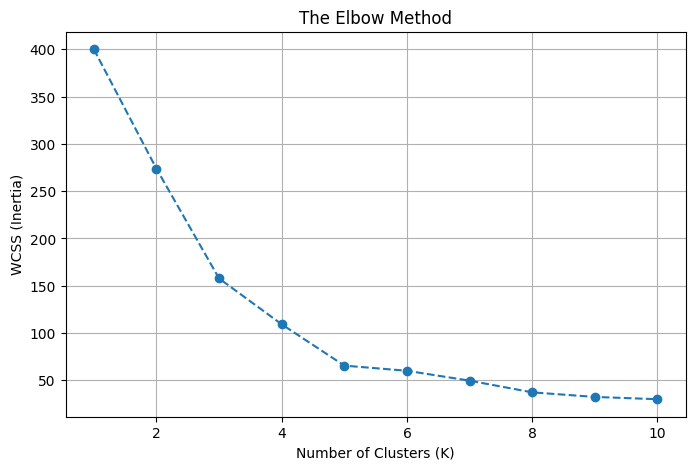

In [11]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

### Step 4: Apply K-Means and Visualize Clusters
Based on the elbow plot, 5 is usually the optimal number of clusters for this dataset. We will fit K-Means with 5 clusters and plot the results.

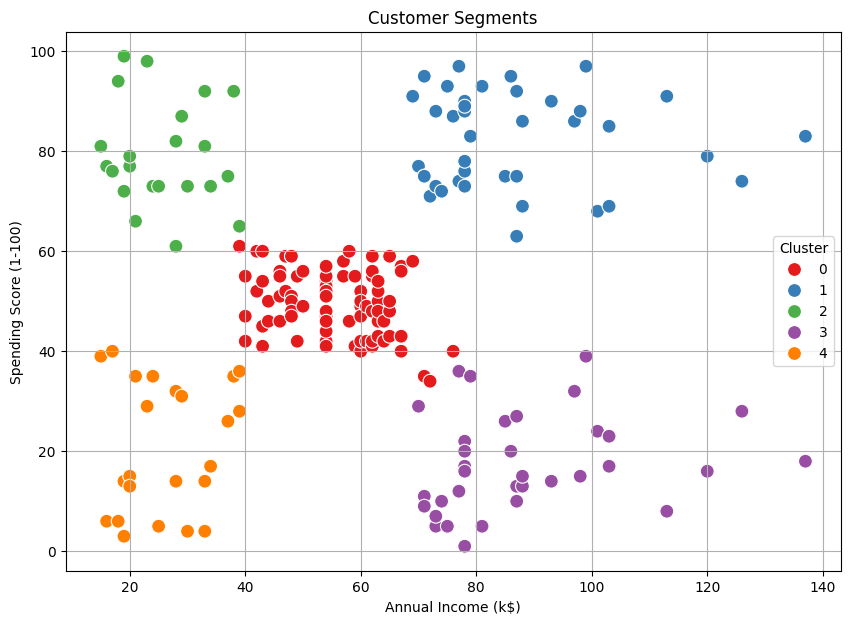

In [12]:
# Train K-Means with 5 clusters
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(X_scaled)

# Add the cluster labels back to our original DataFrame
df['Cluster'] = y_kmeans

# Visualize the clusters
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=df['Cluster'],
    palette='Set1',
    s=100,
    data=df
)
plt.title('Customer Segments')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

### Step 5: Profile Clusters and Save Results
We will calculate the mean values of each cluster to build our profiles, then save the final data to a CSV file.

In [13]:
# Ensure the cluster labels are assigned to the DataFrame
df['Cluster'] = y_kmeans

# Calculate averages for each customer cluster
summary = df.groupby('Cluster').agg({
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Count'})

print("--- Cluster Profiles Summary ---")
display(summary)

# Save labeled data to CSV
df.to_csv('segmented_customers.csv', index=False)
print("Saved segmented results to 'segmented_customers.csv'")

--- Cluster Profiles Summary ---


,Age,Annual Income (k$),Spending Score (1-100),Count
Cluster,,,,
0,42.716049,55.296296,49.518519,81
1,32.692308,86.538462,82.128205,39
2,25.272727,25.727273,79.363636,22
3,41.114286,88.200000,17.114286,35
4,45.217391,26.304348,20.913043,23


Saved segmented results to 'segmented_customers.csv'
